# Practical 3 - Exploratory Data Analysis
Dataset: Diabetes progression - 442 patients, baseline measurements and disease progression after one year

In [1]:
from pathlib import Path
import io
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
def find_data(name):
    """Look for the CSV in the usual places; in Colab, ask for an upload if it is missing."""
    folders = (HERE.parent / "Datasets", HERE / "Datasets", HERE, Path.cwd(),
               Path("/content"), Path("/content/Datasets"), Path("/content/drive/MyDrive"))
    for folder in folders:
        if (folder / name).exists():
            return folder
    try:
        from google.colab import files
        print(f"{name} not found - please choose it in the upload dialog (it is in the Datasets folder).")
        files.upload()
        return Path.cwd()
    except ImportError:
        raise FileNotFoundError(f"Could not find {name}. Put it in a 'Datasets' folder next to this script.")

DATA = find_data("diabetes_progression.csv")
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)

patients = pd.read_csv(DATA / "diabetes_progression.csv")
print(patients.head().to_string())

   patient_id   age  sex   bmi     bp     s1     s2    s3   s4      s5    s6  progression
0           1  59.0  2.0  32.1  101.0  157.0   93.2  38.0  4.0  4.8598  87.0        151.0
1           2  48.0  1.0  21.6   87.0  183.0  103.2  70.0  3.0  3.8918  69.0         75.0
2           3  72.0  2.0  30.5   93.0  156.0   93.6  41.0  4.0  4.6728  85.0        141.0
3           4  24.0  1.0  25.3   84.0  198.0  131.4  40.0  5.0  4.8903  89.0        206.0
4           5  50.0  1.0  23.0  101.0  192.0  125.4  52.0  4.0  4.2905  80.0        135.0


## 1. Structure of the data

In [2]:
buffer = io.StringIO()
patients.info(buf=buffer)
print(buffer.getvalue())
print("Duplicate rows:", int(patients.duplicated().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   patient_id   442 non-null    int64  
 1   age          442 non-null    float64
 2   sex          442 non-null    float64
 3   bmi          442 non-null    float64
 4   bp           442 non-null    float64
 5   s1           442 non-null    float64
 6   s2           442 non-null    float64
 7   s3           442 non-null    float64
 8   s4           442 non-null    float64
 9   s5           442 non-null    float64
 10  s6           442 non-null    float64
 11  progression  442 non-null    float64
dtypes: float64(11), int64(1)
memory usage: 41.6 KB

Duplicate rows: 0


In [3]:
print(patients.drop(columns="patient_id").describe().round(2).to_string())

          age     sex     bmi      bp      s1      s2      s3      s4      s5      s6  progression
count  442.00  442.00  442.00  442.00  442.00  442.00  442.00  442.00  442.00  442.00       442.00
mean    48.52    1.47   26.38   94.65  189.14  115.44   49.79    4.07    4.64   91.26       152.13
std     13.11    0.50    4.42   13.83   34.61   30.41   12.93    1.29    0.52   11.50        77.09
min     19.00    1.00   18.00   62.00   97.00   41.60   22.00    2.00    3.26   58.00        25.00
25%     38.25    1.00   23.20   84.00  164.25   96.05   40.25    3.00    4.28   83.25        87.00
50%     50.00    1.00   25.70   93.00  186.00  113.00   48.00    4.00    4.62   91.00       140.50
75%     59.00    2.00   29.28  105.00  209.75  134.50   57.75    5.00    5.00   98.00       211.50
max     79.00    2.00   42.20  133.00  301.00  242.40   99.00    9.09    6.11  124.00       346.00


## 2. Creating categories
BMI classes follow the usual WHO cut-offs; "high progression" means above the overall median.

In [4]:
patients["bmi_class"] = pd.cut(patients["bmi"], bins=[0, 18.5, 25, 30, 100],
                               labels=["underweight", "normal", "overweight", "obese"], right=False)
median_prog = patients["progression"].median()
patients["progression_level"] = (patients["progression"] > median_prog).map({True: "high", False: "low"})
print("Median progression:", median_prog)
print(patients["bmi_class"].value_counts().reindex(["underweight", "normal", "overweight", "obese"]).to_string())

Median progression: 140.5
bmi_class
underweight      2
normal         186
overweight     155
obese           99


## 3. How many obese patients show high progression?

In [5]:
obese = patients[patients["bmi_class"] == "obese"]
share_obese = (obese["progression_level"] == "high").mean() * 100
rest = patients[patients["bmi_class"] != "obese"]
share_rest = (rest["progression_level"] == "high").mean() * 100

print(f"Obese patients               : {len(obese)}")
print(f"  with high progression      : {share_obese:.2f}%")
print(f"Non-obese patients           : {len(rest)}")
print(f"  with high progression      : {share_rest:.2f}%")
print("Conclusion: progression differs clearly with BMI" if abs(share_obese - share_rest) > 10
      else "Conclusion: little difference")

Obese patients               : 99
  with high progression      : 79.80%
Non-obese patients           : 343
  with high progression      : 41.40%
Conclusion: progression differs clearly with BMI


## 4. BMI class vs progression level

In [6]:
print(pd.crosstab(patients["bmi_class"], patients["progression_level"], margins=True).to_string())

progression_level  high  low  All
bmi_class                        
underweight           0    2    2
normal               49  137  186
overweight           93   62  155
obese                79   20   99
All                 221  221  442


## 5. Age of high- versus low-progression patients

In [7]:
age_stats = patients.groupby("progression_level")["age"].agg(["count", "mean", "std"])
print(age_stats.round(2).to_string())

                   count   mean    std
progression_level                     
high                 221  50.58  12.99
low                  221  46.45  12.93


## 6. Age distribution

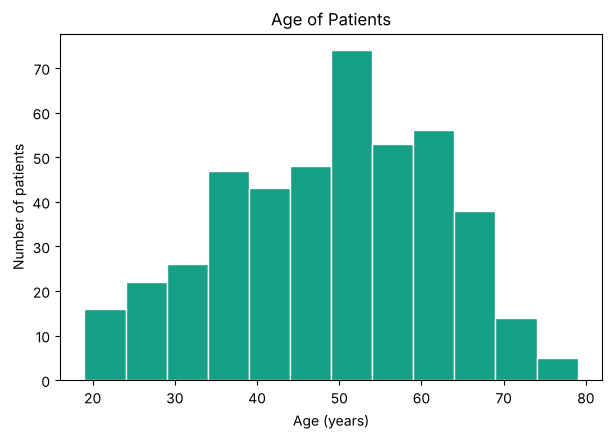

In [8]:
plt.figure(figsize=(7, 4.5))
plt.hist(patients["age"], bins=12, color="#16a085", edgecolor="white")
plt.title("Age of Patients")
plt.xlabel("Age (years)")
plt.ylabel("Number of patients")
plt.savefig(FIG / "age_histogram.png", dpi=120, bbox_inches="tight")
plt.show()

## 7. Bar charts of real group counts

sex
Group 1    235
Group 2    207


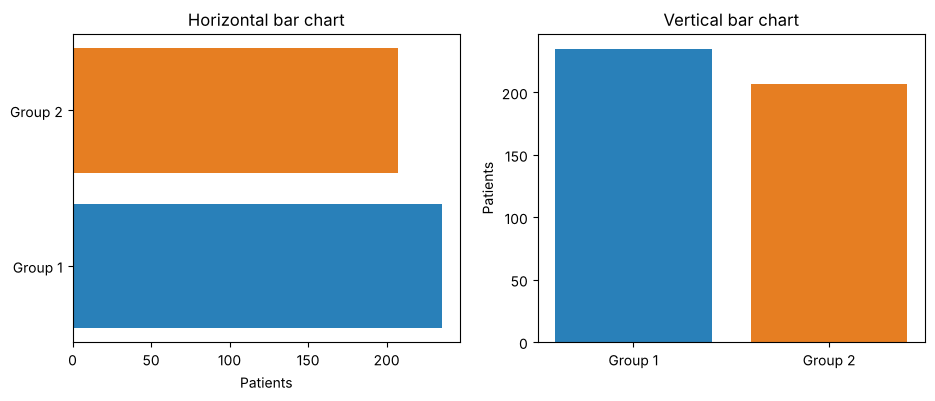

In [9]:
sex_counts = patients["sex"].map({1.0: "Group 1", 2.0: "Group 2"}).value_counts().sort_index()
print(sex_counts.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(sex_counts.index, sex_counts.values, color=["#2980b9", "#e67e22"])
axes[0].set_title("Horizontal bar chart")
axes[0].set_xlabel("Patients")
axes[1].bar(sex_counts.index, sex_counts.values, color=["#2980b9", "#e67e22"])
axes[1].set_title("Vertical bar chart")
axes[1].set_ylabel("Patients")
fig.savefig(FIG / "group_counts.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Median progression of obese patients

In [10]:
print("Median progression (obese)    :", obese["progression"].median())
print("Median progression (all)      :", median_prog)

Median progression (obese)    : 230.0
Median progression (all)      : 140.5
